<a href="https://colab.research.google.com/github/ust-buan-640/buan-640-notebooks/blob/main/notebooks/m11-5-correlation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Correlation

R² and $s_e$ described how well the line fits. The correlation coefficient describes the same linear relationship without fitting a line at all, and it is one of the most quoted numbers in business reports.

*Data: Ames housing data (De Cock, 2011, Journal of Statistics Education), single-family homes in the North Ames neighborhood sold under normal conditions in 2007. `area` is the above-ground living area in square feet, and `price` is the sale price in dollars.*

The same three steps as before: libraries, data, model.

In [1]:
# @title
import pandas as pd
import statsmodels.api as sm

homes = pd.read_csv("https://raw.githubusercontent.com/ust-buan-640/buan-640-notebooks/main/data/north_ames_2007.csv")
model = sm.formula.ols("price ~ area", data=homes).fit()

In [2]:
# @title Setup for the illustrations (colors and helper functions)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import scipy.stats as stats
from matplotlib.patches import FancyBboxPatch

PURPLE, GOLD, GRAY, LIGHT, SAND = "#510C76", "#B07A00", "#6E6E6E", "#C9B8D6", "#EFE3C2"
plt.rcParams.update({"font.size": 14, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#444444", "axes.labelcolor": "#222222",
                     "xtick.color": "#444444", "ytick.color": "#444444",
                     "axes.titlesize": 14, "legend.fontsize": 12})
DOLLARS = mtick.FuncFormatter(lambda v, p: "$0" if v == 0 else ("−" if v < 0 else "") + f"${abs(v)/1000:,.0f}K")


def fit(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float)
    b1 = np.sum((x - x.mean()) * (y - y.mean())) / np.sum((x - x.mean()) ** 2)
    return y.mean() - b1 * x.mean(), b1


def home_axes(ax, xlim=(700, 2400), ylim=(0, 290000)):
    ax.set_xlim(*xlim); ax.set_ylim(*ylim)
    ax.yaxis.set_major_formatter(DOLLARS)
    ax.set_xlabel("living area (sq ft)"); ax.set_ylabel("sale price")


na = pd.read_csv("https://raw.githubusercontent.com/ust-buan-640/buan-640-notebooks/main/data/north_ames_2007.csv")
x, y = na.area.values.astype(float), na.price.values.astype(float)
b0, b1 = fit(x, y)
yhat = b0 + b1 * x
res = y - yhat
XS = np.linspace(700, 2400, 100)
n = len(x)
xbar = x.mean()
ssxx = np.sum((x - xbar) ** 2)
s = np.sqrt(np.sum(res ** 2) / (n - 2))


def box(ax, cx, cy, w, h, text, ec=PURPLE, fc="white", fs=13):
    ax.add_patch(FancyBboxPatch((cx - w / 2, cy - h / 2), w, h, boxstyle="round,pad=0.02,rounding_size=0.08",
                                fc=fc, ec=ec, lw=1.6))
    ax.text(cx, cy, text, ha="center", va="center", fontsize=fs)

def arrow(ax, p, q, color=PURPLE):
    ax.annotate("", xy=q, xytext=p, arrowprops=dict(arrowstyle="-|>", color=color, lw=1.6))

plt.rcParams["figure.dpi"] = 110

## The correlation coefficient

The **correlation coefficient** measures the strength and direction of a *linear* relationship between two quantitative variables. We write $\rho$ (rho) for the population and $r$ for the sample. It is also called Pearson's correlation, after Karl Pearson.

$$r = \frac{SS_{xy}}{\sqrt{SS_{xx}\, SS_{yy}}} = \frac{\sum (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum (x_i - \bar{x})^2 \sum (y_i - \bar{y})^2}}$$

- It always lies between −1 and 1. The sign gives the direction; the distance from 0 gives the strength.
- It has no units, so it does not change if price is measured in thousands of dollars or area in square meters.
- It does not change if we swap $x$ and $y$.

For North Ames, $r = 0.77$: a fairly strong positive linear relationship between living area and sale price. In Excel, `=CORREL(x range, y range)`; in pandas, `.corr()`.

In [3]:
# @title
homes["area"].corr(homes["price"])

np.float64(0.7690689518008696)

## What different values of r look like

$r = +1$ or $-1$ only when every point lies exactly on a line.

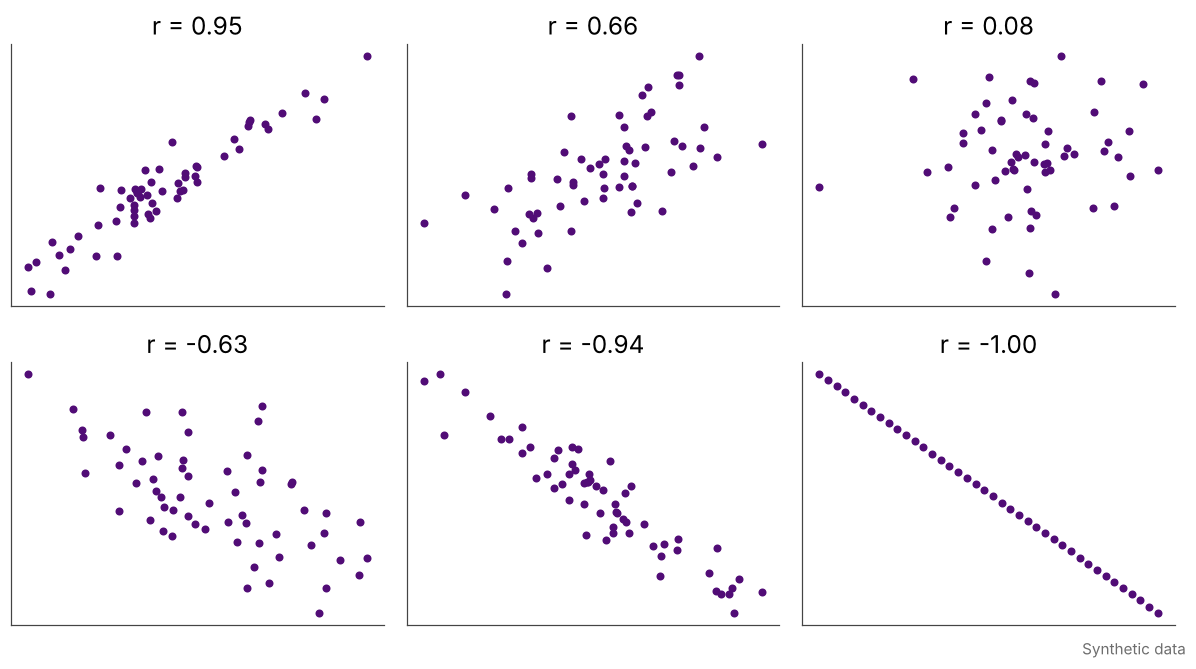

In [4]:
# @title Show the plotting code
# ---------------- 7. correlation ----------------
rng7 = np.random.default_rng(7)
def corr_sample(rho, m=60):
    z = rng7.multivariate_normal([0, 0], [[1, rho], [rho, 1]], m)
    return z[:, 0], z[:, 1]
sets = [corr_sample(0.95), corr_sample(0.6), corr_sample(0.0), corr_sample(-0.6), corr_sample(-0.95)]
xl = np.linspace(-2, 2, 40); sets.append((xl, -xl))
fig, axs = plt.subplots(2, 3, figsize=(11, 6))
for ax, (u, v) in zip(axs.ravel(), sets):
    ax.scatter(u, v, color=PURPLE, s=18)
    ax.set_title(f"r = {stats.pearsonr(u, v)[0]:.2f}", fontsize=16); ax.set_xticks([]); ax.set_yticks([])
fig.text(0.99, -0.01, "Synthetic data", ha="right", fontsize=10, color=GRAY)
fig.tight_layout(); plt.show()  # f26_r_values.png

## Correlation sees only straight lines

In both panels $y$ is completely determined by $x$, and $r = 0$. So $r = 0$ means no *linear* relationship, not no relationship.

- If $\rho \ne 0$, the two variables are dependent: knowing one tells us something about the other.
- If $\rho = 0$, they can still be dependent, as in both panels here.
- Independent variables always have $\rho = 0$, but not the other way around.

This is one more reason to look at the scatterplot before computing anything.

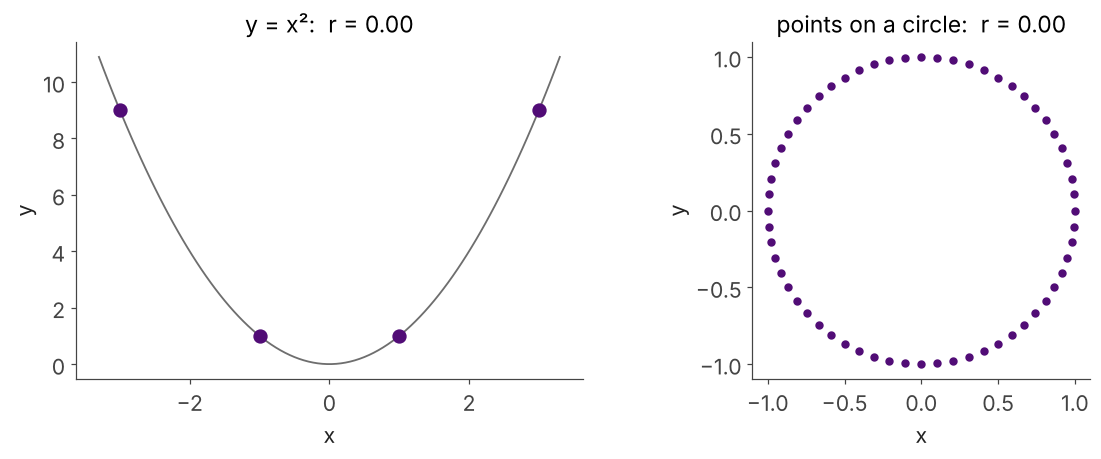

In [5]:
# @title Show the plotting code
fig, axs = plt.subplots(1, 2, figsize=(11, 4.4))
xq = np.array([-3, -1, 1, 3], float)
xsq = np.linspace(-3.3, 3.3, 100)
axs[0].plot(xsq, xsq ** 2, color=GRAY, lw=1.2); axs[0].scatter(xq, xq ** 2, color=PURPLE, s=70, zorder=3)
axs[0].set_title("y = x²:  r = 0.00", fontsize=15)
th = np.linspace(0, 2 * np.pi, 60, endpoint=False)
axs[1].scatter(np.cos(th), np.sin(th), color=PURPLE, s=20); axs[1].set_aspect("equal")
axs[1].set_title("points on a circle:  r = 0.00", fontsize=15)
for ax in axs: ax.set_xlabel("x"); ax.set_ylabel("y")
fig.tight_layout(); plt.show()  # f27_r_zero.png

## Correlation is not the slope

The slope and the correlation are connected:

$$b_1 = r\,\frac{s_y}{s_x}$$

where $s_y$ and $s_x$ are the ordinary standard deviations of $y$ and $x$. For North Ames, $0.769 \times 27{,}910 / 335.7 = 63.94$, the slope we found.

So the slope and $r$ always have the same sign. But the slope also carries the units of $x$ and $y$, while $r$ has none, and a steeper line does not mean a stronger relationship. Below, the gentle line on the left has a stronger correlation than the steep line on the right.

In [6]:
# @title
r = homes["area"].corr(homes["price"])
s_x = homes["area"].std()
s_y = homes["price"].std()
print(f"r = {r:.4f},  s_x = {s_x:.1f},  s_y = {s_y:,.0f},  r * s_y / s_x = {r * s_y / s_x:.2f}")
print(f"slope from the model: {model.params['area']:.2f}")

r = 0.7691,  s_x = 335.7,  s_y = 27,910,  r * s_y / s_x = 63.94
slope from the model: 63.94


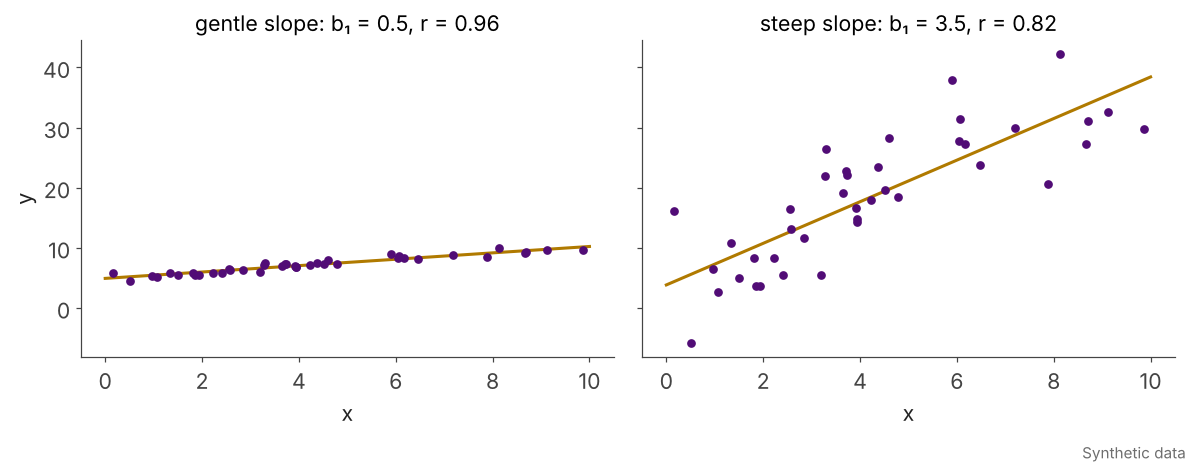

In [7]:
# @title Show the plotting code
rng8 = np.random.default_rng(8)
u = rng8.uniform(0, 10, 40); noise = rng8.normal(0, 1, 40)
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, (sl, sd, ttl) in zip(axs, [(0.5, 0.4, "gentle slope"), (3.0, 6.0, "steep slope")]):
    v = 5 + sl * u + sd * noise
    aa, bb = fit(u, v)
    ax.scatter(u, v, color=PURPLE, s=22, zorder=3); ax.plot([0, 10], [aa, aa + 10 * bb], color=GOLD, lw=2)
    ax.set_title(f"{ttl}: b₁ = {bb:.1f}, r = {stats.pearsonr(u, v)[0]:.2f}", fontsize=14)
    ax.set_xlabel("x")
axs[0].set_ylabel("y")
fig.text(0.99, -0.02, "Synthetic data", ha="right", fontsize=10, color=GRAY)
fig.tight_layout(); plt.show()  # f28_slope_vs_r.png

## Correlation and R²

With one explanatory variable, $R^2 = r^2$: for North Ames, $0.769^2 = 0.59$. Going back, $r = \pm\sqrt{R^2}$, with the sign of the slope.

Excel's regression output reports **Multiple R**, which is $\sqrt{R^2}$. With one explanatory variable it equals $|r|$, so it is never negative; when the slope is negative, $r$ is minus Multiple R.

In [8]:
# @title
print(f"r squared = {r ** 2:.4f}")
print(f"R-squared = {model.rsquared:.4f}")

r squared = 0.5915
R-squared = 0.5915


## Correlation and causation

A correlation, like a slope, describes an association. As we saw when we discussed experimental design, two variables can be correlated because one causes the other, because a third variable affects both, or by coincidence; the correlation alone cannot tell these apart.